<a href="https://colab.research.google.com/github/tahta-id/Project-Google-Colab/blob/main/Jurnal.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Saving data_jurnal_clean.csv to data_jurnal_clean.csv
(100, 4)
ASLI   : Interesterification Process of Palm Oil Into Biodiesel with Co-solvent Methyl Esters. One alternative energy that is currently being developed is fatty acid methyl ester (FAME), commonly known as biodiesel. The process of making biodiesel which has so far been carried out is a process of transesteri
TOKEN  : ['interesterification', 'process', 'of', 'palm', 'oil', 'into', 'biodiesel', 'with', 'co', 'solvent', 'methyl', 'esters', 'one', 'alternative', 'energy', 'that', 'is', 'currently', 'being', 'developed', 'is', 'fatty', 'acid', 'methyl', 'ester']
BERSIH : interesterification process palm oil biodiesel solvent methyl esters one alternative energy currently developed fatty acid methyl ester fame commonly known biodiesel process making biodiesel far carried process transesterification alcohol byproduct produced glycerol glycerol must completely separate
Matriks TF-IDF: (100, 3471)


modules.json:   0%|          | 0.00/229 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/122 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/3.89k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

...

Batches:   0%|          | 0/4 [00:00<?, ?it/s]

Embedding: (100, 384)
QUERY: pembelajaran daring mahasiswa -> ['ajar', 'daring', 'mahasiswa']

[TF-IDF]
  1. (doc 78, 2022.0) skor=0.0902 | Pengaruh Persepsi Manfaat, Persepsi Kemudahan Penggunaan Dan Fitur Layanan Terhadap Keputu
  2. (doc 26, 2019.0) skor=0.0873 | Efektivitas hasil belajar IPS melalui penggunaan model pembelajaran snowball throwing pada
  3. (doc 57, 2021.0) skor=0.0760 | Penerapan Model Pembelajaran Critical Thinking untuk Meningkatkan Hasil Belajar Siswa dala
  4. (doc 71, 2017.0) skor=0.0721 | MODEL PEMBELAJARAN PROJECT BASED LEARNING BERBASIS POTENSI LOKAL PADA MATA PELAJARAN PRAKA
  5. (doc 33, 2016.0) skor=0.0546 | Keefektifan Metode Penemuan Terbimbing dan Metode Pemberian Tugas pada Pembelajaran Bangun

[BM25]
  1. (doc 78, 2022.0) skor=4.4584 | Pengaruh Persepsi Manfaat, Persepsi Kemudahan Penggunaan Dan Fitur Layanan Terhadap Keputu
  2. (doc 26, 2019.0) skor=4.0857 | Efektivitas hasil belajar IPS melalui penggunaan model pembelajaran snowball throwing pada

,query,method,mean_query_term_coverage,docs_without_query_term
0,pembelajaran daring mahasiswa,TF-IDF,0.200,4
1,pembelajaran daring mahasiswa,BM25,0.200,4
2,pembelajaran daring mahasiswa,BERT+ANN,0.100,7
3,analisis sentimen media sosial,TF-IDF,0.125,5
4,analisis sentimen media sosial,BM25,0.125,5
5,analisis sentimen media sosial,BERT+ANN,0.025,9
6,klasifikasi menggunakan machine learning,TF-IDF,0.333,0
7,klasifikasi menggunakan machine learning,BM25,0.333,0
8,klasifikasi menggunakan machine learning,BERT+ANN,0.233,3


,mean_query_term_coverage,docs_without_query_term
method,,
BERT+ANN,0.119,6.333
BM25,0.219,3.000
TF-IDF,0.219,3.000


pair,BM25 vs BERT+ANN,TF-IDF vs BERT+ANN,TF-IDF vs BM25
query,,,
analisis sentimen media sosial,0.111,0.111,1.000
klasifikasi menggunakan machine learning,0.333,0.250,0.818
pembelajaran daring mahasiswa,0.176,0.176,1.000


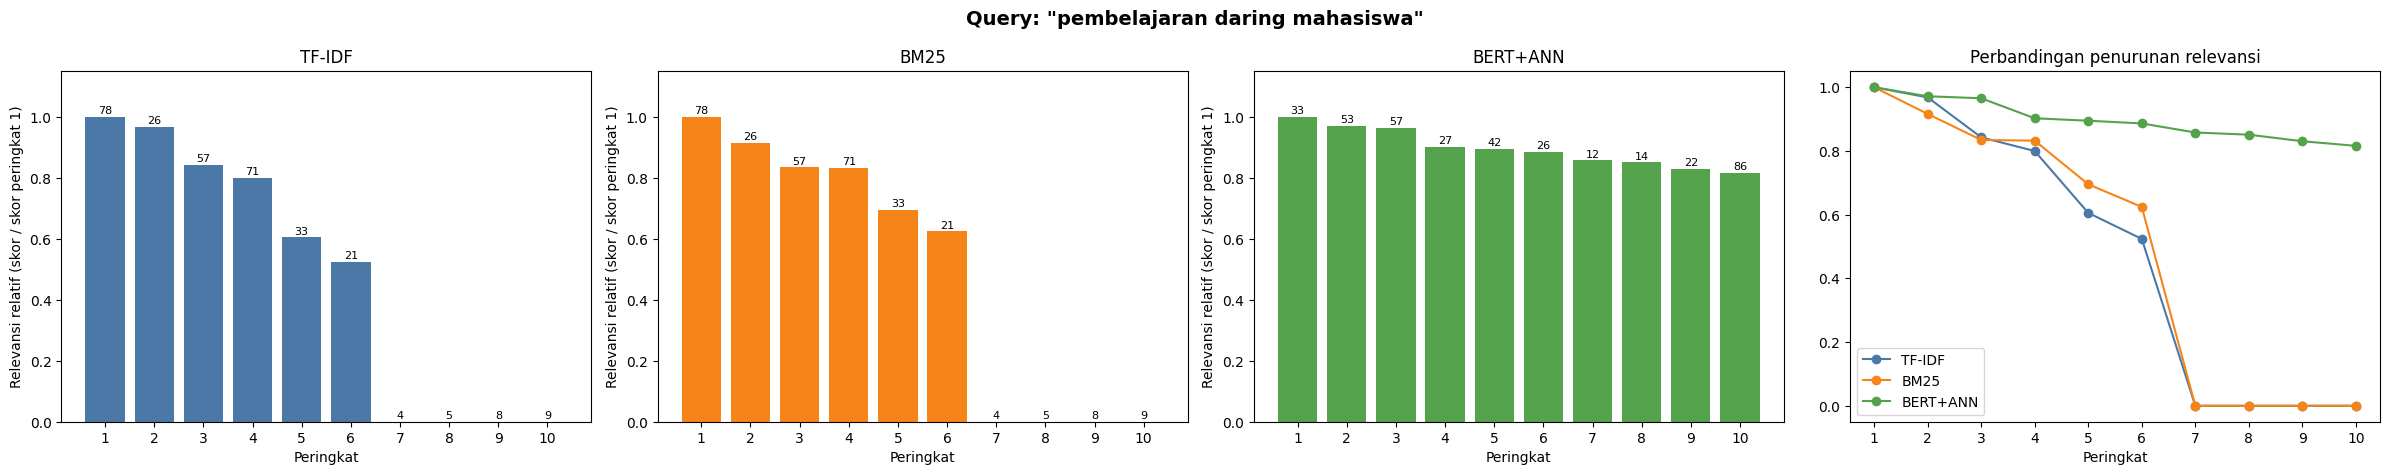

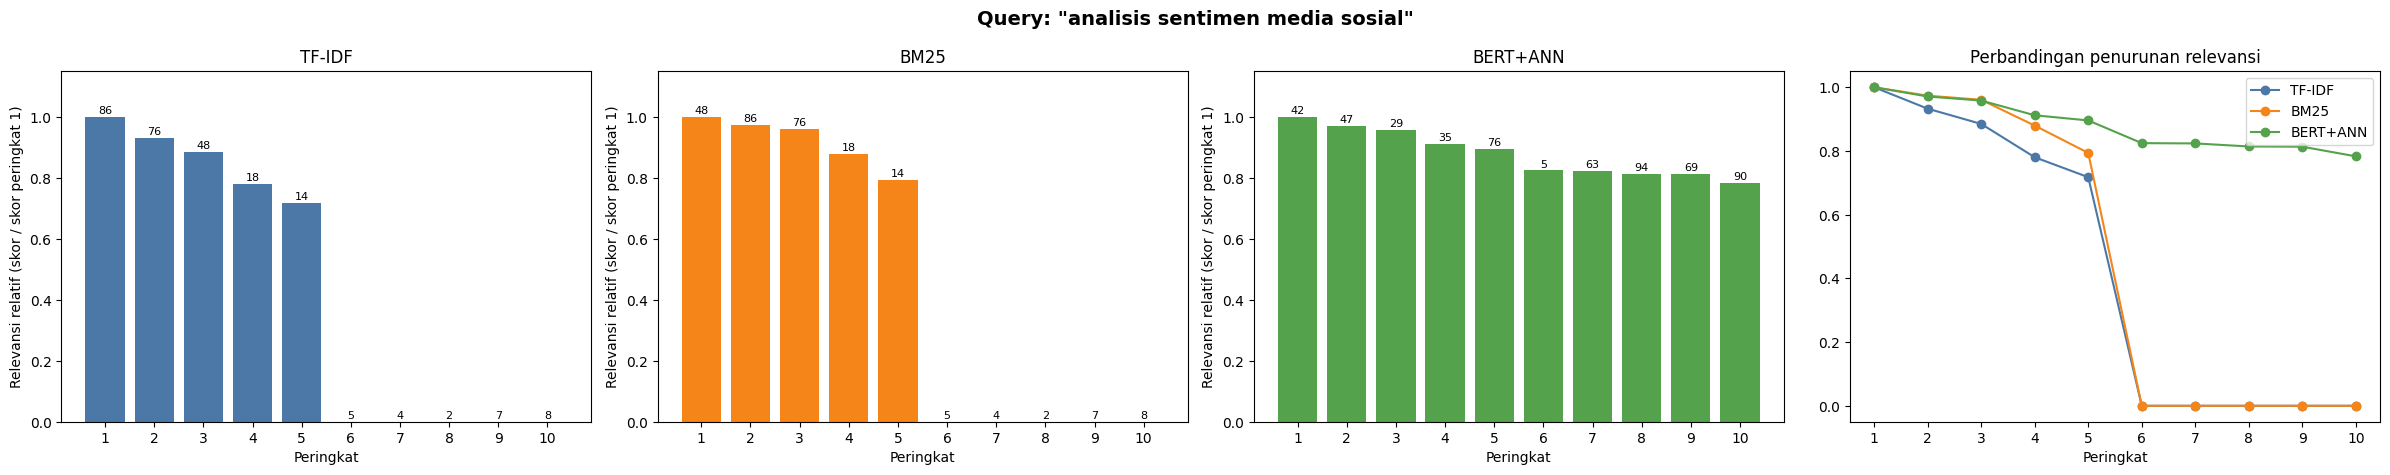

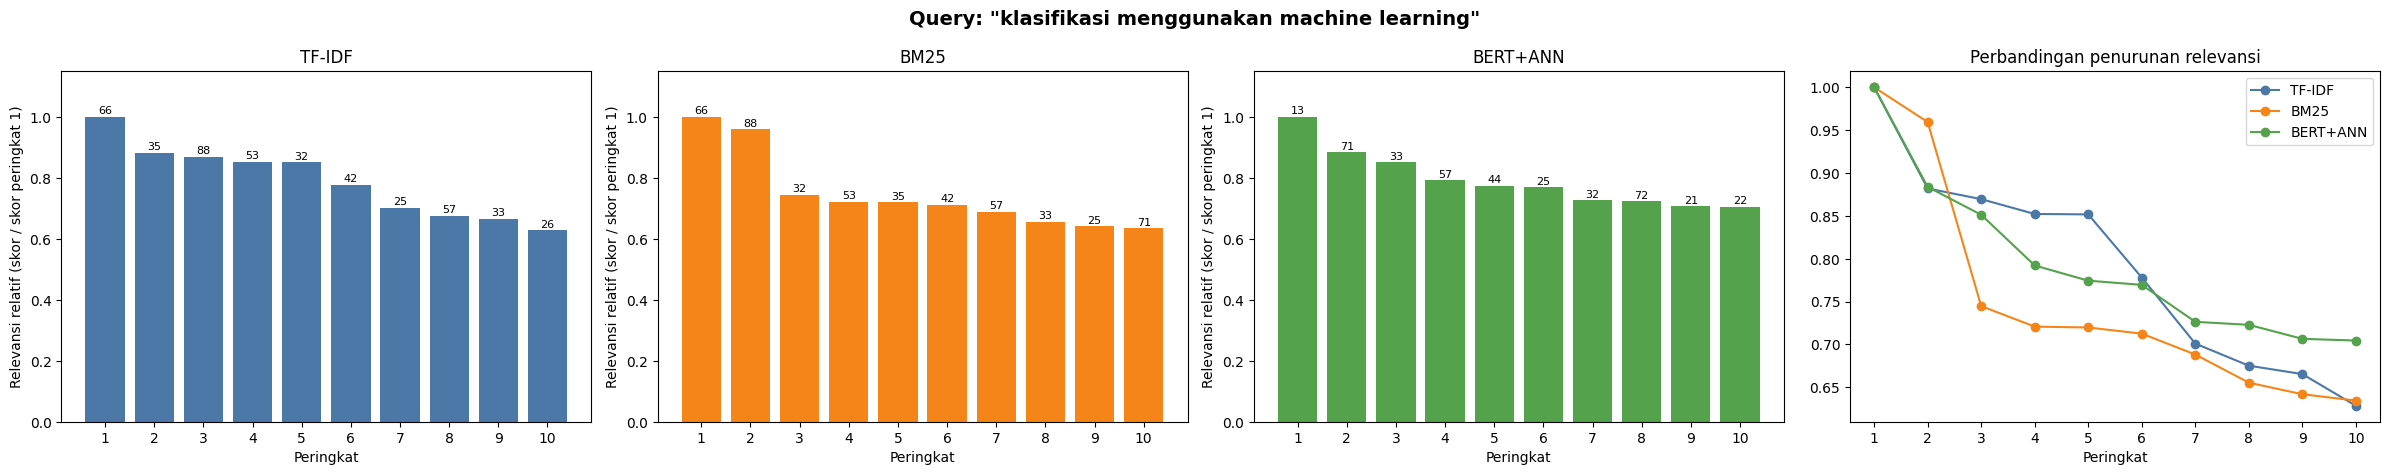

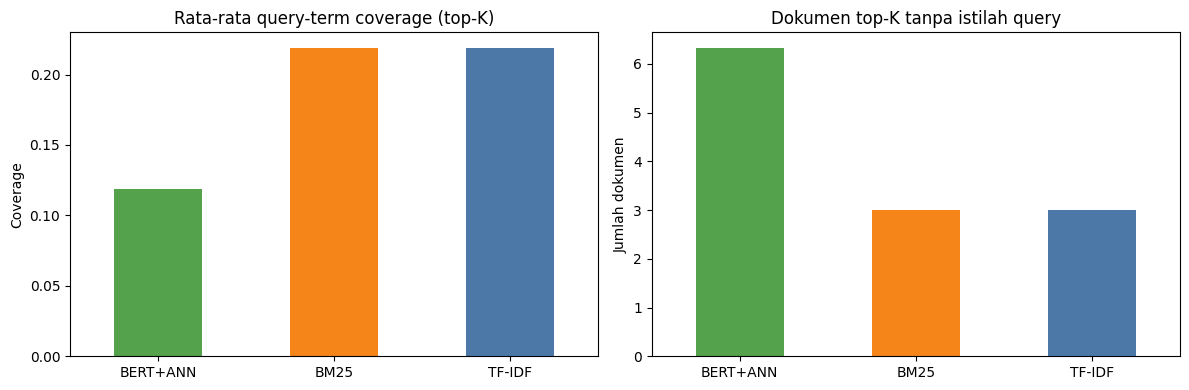

In [ ]:
# %% [markdown]
# # Information Retrieval Jurnal: TF-IDF vs BM25 vs BERT + ANN
#
# Dataset: 100 jurnal dengan variabel `year, title, authors, abstract, abstract_clean`.
#
# Alur:
# 1. Preprocessing: tokenisasi, stopword removal, lemmatization
# 2. Sparse retrieval: TF-IDF + cosine similarity
# 3. Probabilistic retrieval: BM25
# 4. Dense retrieval: BERT embedding + ANN search (FAISS HNSW)
# 5. Perbandingan hasil dan visualisasi ranking/relevansi per metode

# %% [markdown]
# ## 1. Instalasi & import

# %%
!pip -q install Sastrawi nltk rank_bm25 sentence-transformers faiss-cpu

# %%
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from itertools import combinations

import nltk
nltk.download("stopwords", quiet=True)
nltk.download("wordnet", quiet=True)
nltk.download("omw-1.4", quiet=True)

# ===== KONFIGURASI =====
LANG = "id"        # "id" = jurnal berbahasa Indonesia (stemming Sastrawi), "en" = Inggris (WordNet lemmatizer)
N_DOCS = 100       # jumlah dokumen
TOP_K = 10         # jumlah hasil yang ditampilkan per query
SEED = 42
DATA_PATH = None   # isi path CSV jika sudah ada di Drive/Colab, contoh: "/content/data_jurnal_clean.csv"
                   # kalau None, akan muncul dialog upload file

# %% [markdown]
# ## 2. Load dataset (ambil 100 data)
#
# File CSV minimal punya kolom judul dan abstrak. Nama kolom `author`, `judul`, `tahun`, `abstrak` otomatis dipetakan.
# Untuk dataset SINTA (Zenodo) yang berukuran besar, upload lewat Google Drive agar lebih cepat:
# ```python
# from google.colab import drive; drive.mount("/content/drive")
# DATA_PATH = "/content/drive/MyDrive/data_jurnal_clean.csv"
# ```

# %%
if DATA_PATH is None:
    from google.colab import files
    uploaded = files.upload()
    DATA_PATH = list(uploaded.keys())[0]

df_raw = pd.read_csv(DATA_PATH)
df_raw.columns = [c.strip().lower() for c in df_raw.columns]
df_raw = df_raw.rename(columns={"author": "authors", "penulis": "authors", "judul": "title",
                                "tahun": "year", "abstrak": "abstract"})

for col in ["title", "abstract"]:
    assert col in df_raw.columns, f"Kolom '{col}' tidak ditemukan. Kolom tersedia: {list(df_raw.columns)}"
for col in ["year", "authors"]:
    if col not in df_raw.columns:
        df_raw[col] = ""

df_raw = df_raw.dropna(subset=["title", "abstract"])
df_raw = df_raw[df_raw["abstract"].astype(str).str.split().str.len() >= 30]   # buang abstrak terlalu pendek

df = (df_raw.sample(N_DOCS, random_state=SEED)
            .reset_index(drop=True)[["year", "title", "authors", "abstract"]])
print(df.shape)
df.head()

# %% [markdown]
# ## 3. Preprocessing
#
# Tahapan: lowercase, hapus angka/simbol, **tokenisasi**, **stopword removal**, **lemmatization**
# (untuk bahasa Indonesia, lemmatization dilakukan dengan stemmer Sastrawi).

# %%
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from Sastrawi.Stemmer.StemmerFactory import StemmerFactory
from Sastrawi.StopWordRemover.StopWordRemoverFactory import StopWordRemoverFactory

EXTRA_STOP = {"penelitian", "hasil", "metode", "menggunakan", "berdasarkan", "dilakukan",
              "study", "paper", "result", "research", "using", "based"}

stop_words = set(stopwords.words("english")) | EXTRA_STOP
if LANG == "id":
    stop_words |= set(StopWordRemoverFactory().get_stop_words())

stemmer = StemmerFactory().create_stemmer()
wnl = WordNetLemmatizer()
_cache = {}

def lemmatize(tok):
    if tok not in _cache:
        _cache[tok] = stemmer.stem(tok) if LANG == "id" else wnl.lemmatize(tok)
    return _cache[tok]

def tokenize(text):
    return re.findall(r"[a-z]+", str(text).lower())

def preprocess(text):
    tokens = tokenize(text)                                   # 1) tokenisasi
    tokens = [t for t in tokens if len(t) > 2 and t not in stop_words]   # 2) stopword removal
    return [lemmatize(t) for t in tokens]                     # 3) lemmatization

df["abstract_clean"] = df["abstract"].apply(lambda x: " ".join(preprocess(x)))

# Korpus untuk sparse retrieval = token judul + token abstrak_clean
doc_tokens = [preprocess(t) + ac.split() for t, ac in zip(df["title"], df["abstract_clean"])]
corpus_clean = [" ".join(toks) for toks in doc_tokens]

df[["year", "title", "authors", "abstract", "abstract_clean"]].head(3)

# %%
# Contoh sebelum dan sesudah preprocessing
i = 0
print("ASLI   :", df.abstract[i][:300])
print("TOKEN  :", tokenize(df.abstract[i])[:25])
print("BERSIH :", df.abstract_clean[i][:300])

# %% [markdown]
# ## 4. Sparse retrieval: TF-IDF + cosine similarity

# %%
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

tfidf = TfidfVectorizer(token_pattern=r"\S+", sublinear_tf=True)
X_tfidf = tfidf.fit_transform(corpus_clean)
print("Matriks TF-IDF:", X_tfidf.shape)

def search_tfidf(query, k=TOP_K):
    q = " ".join(preprocess(query))
    scores = cosine_similarity(tfidf.transform([q]), X_tfidf).ravel()
    ids = np.argsort(-scores)[:k]
    return ids, scores[ids]

# %% [markdown]
# ## 5. Probabilistik: BM25

# %%
from rank_bm25 import BM25Okapi

bm25 = BM25Okapi(doc_tokens, k1=1.5, b=0.75)

def search_bm25(query, k=TOP_K):
    scores = bm25.get_scores(preprocess(query))
    ids = np.argsort(-scores)[:k]
    return ids, scores[ids]

# %% [markdown]
# ## 6. Dense retrieval: BERT embedding + ANN search
#
# Embedding dibuat dari teks asli (judul + abstrak, tanpa stemming) karena model BERT memahami konteks kalimat utuh.
# Model multibahasa dipakai agar mendukung bahasa Indonesia dan Inggris. Indeks ANN memakai FAISS HNSW.

# %%
from sentence_transformers import SentenceTransformer
import faiss

bert = SentenceTransformer("paraphrase-multilingual-MiniLM-L12-v2")

texts_raw = (df["title"] + ". " + df["abstract"]).tolist()
emb = bert.encode(texts_raw, normalize_embeddings=True, show_progress_bar=True).astype("float32")
print("Embedding:", emb.shape)

index = faiss.IndexHNSWFlat(emb.shape[1], 32, faiss.METRIC_INNER_PRODUCT)  # ANN: graf HNSW
index.hnsw.efConstruction = 200
index.add(emb)
index.hnsw.efSearch = 64

def search_dense(query, k=TOP_K):
    q = bert.encode([query], normalize_embeddings=True).astype("float32")
    scores, ids = index.search(q, k)
    return ids[0], scores[0]

# %% [markdown]
# ## 7. Jalankan pencarian

# %%
# Ganti query sesuai topik jurnal pada dataset Anda
QUERIES = [
    "pembelajaran daring mahasiswa",
    "analisis sentimen media sosial",
    "klasifikasi menggunakan machine learning",
]

METHODS = {"TF-IDF": search_tfidf, "BM25": search_bm25, "BERT+ANN": search_dense}

results = {q: {m: fn(q, TOP_K) for m, fn in METHODS.items()} for q in QUERIES}

def show(q, n=5):
    print("=" * 100)
    print("QUERY:", q, "->", preprocess(q))
    for m, (ids, sc) in results[q].items():
        print(f"\n[{m}]")
        for r, (i, s) in enumerate(zip(ids[:n], sc[:n]), 1):
            print(f"  {r}. (doc {i}, {df.year[i]}) skor={s:.4f} | {df.title[i][:90]}")

for q in QUERIES:
    show(q)

# %%
# Cek kualitas ANN: seberapa mirip hasil HNSW dibanding pencarian eksak (brute force)
recalls = []
for q in QUERIES:
    qv = bert.encode([q], normalize_embeddings=True).astype("float32")[0]
    exact = set(np.argsort(-(emb @ qv))[:TOP_K])
    approx = set(results[q]["BERT+ANN"][0])
    recalls.append(len(exact & approx) / TOP_K)
print("Recall@K ANN vs exact:", np.round(recalls, 2))

# %% [markdown]
# ## 8. Perbandingan metode
#
# Metrik pendukung (tanpa label relevansi manual):
# - **Query-term coverage**: rata-rata porsi istilah query yang benar-benar muncul di dokumen top-K. Nilai tinggi = hasil berbasis kecocokan istilah.
# - **Docs without query term**: jumlah dokumen top-K yang tidak memuat satu pun istilah query. Jika dense retrieval menampilkan dokumen seperti ini yang tetap relevan secara judul/abstrak, itu indikasi pencarian kontekstual.
# - **Overlap (Jaccard)** antar metode pada top-K.

# %%
rows = []
for q in QUERIES:
    qt = set(preprocess(q))
    for m, (ids, sc) in results[q].items():
        cov = [len(qt & set(doc_tokens[i])) / max(len(qt), 1) for i in ids]
        rows.append({"query": q, "method": m,
                     "mean_query_term_coverage": round(float(np.mean(cov)), 3),
                     "docs_without_query_term": int(sum(c == 0 for c in cov))})
cmp_df = pd.DataFrame(rows)
display(cmp_df)

summary = cmp_df.groupby("method")[["mean_query_term_coverage", "docs_without_query_term"]].mean().round(3)
display(summary)

jac = []
for q in QUERIES:
    for a, b in combinations(METHODS, 2):
        A, B = set(results[q][a][0]), set(results[q][b][0])
        jac.append({"query": q, "pair": f"{a} vs {b}", "jaccard_topK": round(len(A & B) / len(A | B), 3)})
display(pd.DataFrame(jac).pivot(index="query", columns="pair", values="jaccard_topK"))

# %% [markdown]
# ## 9. Visualisasi ranking dan relevansi

# %%
colors = {"TF-IDF": "#4C78A8", "BM25": "#F58518", "BERT+ANN": "#54A24B"}

def rel_score(sc):
    # skor relatif terhadap peringkat 1 (agar skala antar metode sebanding)
    return sc / sc[0] if sc[0] > 0 else sc

for q in QUERIES:
    fig, axes = plt.subplots(1, 4, figsize=(24, 4.8))
    fig.suptitle(f'Query: "{q}"', fontsize=14, fontweight="bold")

    for ax, (m, (ids, sc)) in zip(axes[:3], results[q].items()):
        rel = rel_score(sc)
        ax.bar(range(1, TOP_K + 1), rel, color=colors[m])
        for r, (i, v) in enumerate(zip(ids, rel), 1):
            ax.text(r, v + 0.01, str(i), ha="center", fontsize=8)   # angka = id dokumen
        ax.set_title(m)
        ax.set_xlabel("Peringkat")
        ax.set_ylabel("Relevansi relatif (skor / skor peringkat 1)")
        ax.set_xticks(range(1, TOP_K + 1))
        ax.set_ylim(0, 1.15)

    ax = axes[3]
    for m, (ids, sc) in results[q].items():
        ax.plot(range(1, TOP_K + 1), rel_score(sc), marker="o", label=m, color=colors[m])
    ax.set_title("Perbandingan penurunan relevansi")
    ax.set_xlabel("Peringkat")
    ax.set_xticks(range(1, TOP_K + 1))
    ax.legend()
    plt.tight_layout()
    plt.show()

# %%
# Grafik ringkasan: kecocokan istilah query pada top-K tiap metode
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
summary["mean_query_term_coverage"].plot(kind="bar", ax=axes[0], color=[colors[m] for m in summary.index])
axes[0].set_title("Rata-rata query-term coverage (top-K)")
axes[0].set_ylabel("Coverage")
summary["docs_without_query_term"].plot(kind="bar", ax=axes[1], color=[colors[m] for m in summary.index])
axes[1].set_title("Dokumen top-K tanpa istilah query")
axes[1].set_ylabel("Jumlah dokumen")
for ax in axes:
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()

# %% [markdown]
# ## 10. Cara membaca hasil
#
# Hipotesis yang diuji pada notebook ini:
# - **BM25 menangkap istilah spesifik**: dokumen peringkat atas biasanya memuat istilah query secara eksplisit dan skornya turun tajam setelah beberapa dokumen teratas (kurva BM25 pada grafik ke-4 lebih curam). Penyebabnya adalah penalti panjang dokumen dan saturasi frekuensi term.
# - **TF-IDF cenderung noise**: cosine similarity pada vektor TF-IDF dipengaruhi banyak kata umum dan panjang dokumen, sehingga skor lebih datar dan urutan bawah kurang diskriminatif. Lihat kurva relevansi yang melandai dan overlap yang rendah terhadap BM25.
# - **Dense retrieval lebih kontekstual**: BERT dapat menampilkan dokumen yang relevan secara makna walau tidak memuat kata query persis (angka `docs_without_query_term` lebih besar). Periksa judulnya pada tabel hasil untuk memastikan dokumen tersebut memang relevan.
#
# Catatan: karena data hanya 100 dokumen dan tidak ada label relevansi manual, kesimpulan sebaiknya dikonfirmasi dengan membaca judul/abstrak hasil. Untuk evaluasi kuantitatif (Precision@K, nDCG), buat label relevansi untuk tiap query.
